# SST bracket of the pretrained models

The SST bracket $[L(b), U(b)]$ (see `src/experiment.py`'s `sst_bracket`) of the externally pretrained speaker-verification models (`slurm/pretrained-{resnet34,w2vbert,wavlm}-*.submit`), over the signal one shuffled block of $b$ frames spans:

- $L(b) = EER(GS_b) - EER(GO_b)$: lower estimate, the splicing artefacts largely cancel.
- $U(b) = EER(BS_b) - EER(OS)$: upper estimate, also counts the artefacts at the joins.
- $L_{norm}$, $U_{norm}$: both divided by the headroom to chance, $50\% - EER(OS)$, so they compare across models of different baseline EER.

The test EERs come from the per-run summaries (`run{i}/final/SV_EER_test-*`) of the wandb runs. These are also logged by runs still in progress, so the bands use every completed run and average the measures over runs.

The stars mark each model's onset: scanning from large to small blocks, the first block span at which $L(b) > 0$ beyond trial noise, i.e. the lower end of $L(b)$'s 95% trial-bootstrap interval (see `src/experiment.py`'s `sst_bootstrap_intervals`) is $> 0$ in every run.

In [1]:
import sys
from dataclasses import fields
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import wandb

ROOT = Path.cwd().parent  # notebook runs from doc/
sys.path.insert(0, str(ROOT))

from src.config import TransformationConfig
from src.data.segments import BLOCK_SIZES
from src.experiment import sst_bracket

WANDB_PATH = "marbetschar-zhaw/speaker-verification"
VARIANT = "2s"  # wandb.run_postfix of the configs: "2s", "3s" or "2s-vox1o"
MODELS = {  # label: model.type
    "ResNet34 (WeSpeaker)": "WeSpeakerResNet34",
    "w2v-BERT 2.0": "W2VBertSV",
    "WavLM-ECAPA": "WavLMECAPA",
}

In [2]:
def fetch_bracket(api, model_type, variant):
    """SST measures of the latest wandb run of model_type and variant: {measure: (block
    span [ms], mean over runs [%-points or %])}, plus "GO"/"GS": (block span [ms],
    EER(GO_b)/EER(GS_b) [%], "OS": EER(OS) [%] and "onset": the largest
    block span [ms] at which L(b) > 0 holds beyond trial noise (see
    mark_onset), and the run. None if there is
    no run, or it hasn't completed a run yet."""
    runs = api.runs(WANDB_PATH, filters={"display_name": f"{model_type}-voxceleb-OS-{variant}"}, order="-created_at")
    if not runs:
        return None, None
    run = runs[0]
    summary = run.summary._json_dict
    prefix = "/final/SV_EER_test-"
    run_eers = {}
    for key, value in summary.items():
        if key.startswith("run") and prefix in key:
            run_idx, strategy = key.split(prefix)
            run_eers.setdefault(run_idx, {})[strategy] = value / 100
    if not run_eers:
        return None, run
    transformation_config = {f.name: run.config["transformation"][f.name] for f in fields(TransformationConfig) if f.name in run.config["transformation"]}
    transformation = TransformationConfig(**transformation_config)
    measures = {}
    for block_size in BLOCK_SIZES:
        per_run = [sst_bracket(eers, block_size) for eers in run_eers.values()]
        for measure in per_run[0]:
            mean = np.mean([values[measure] for values in per_run]) * 100
            measures.setdefault(measure, []).append((transformation.block_span_s(block_size) * 1000, mean))
        for strategy in ("GO", "GS"):
            if all(f"{strategy}{block_size}" in eers for eers in run_eers.values()):
                mean = np.mean([eers[f"{strategy}{block_size}"] for eers in run_eers.values()]) * 100
                measures.setdefault(strategy, []).append((transformation.block_span_s(block_size) * 1000, mean))
    measures["OS"] = np.mean([eers["OS"] for eers in run_eers.values()]) * 100
    measures["onset"] = None
    for block_size in sorted(BLOCK_SIZES, reverse=True):
        ci_lows = [summary.get(f"{run_idx}/final/SST_L_b{block_size}_ci_low") for run_idx in run_eers]
        if all(ci_low is not None and ci_low > 0 for ci_low in ci_lows):
            measures["onset"] = transformation.block_span_s(block_size) * 1000
            break
    return {measure: points if measure in ("OS", "onset") else tuple(np.array(v) for v in zip(*points)) for measure, points in measures.items()}, (run, len(run_eers))


def mark_onset(ax, bracket, measure, color=None, label=None):
    """Star on bracket[measure] (L or L_norm) at the onset: the largest block
    span, scanning from large to small blocks, at which the lower end of L(b)'s
    95% trial-bootstrap interval (run{i}/final/SST_L_b{b}_ci_low) is > 0 in
    every run. L_norm has the same sign as L, so the onset is the same."""
    if bracket["onset"] is None:
        return
    span, values = bracket[measure]
    ax.plot(bracket["onset"], values[span == bracket["onset"]][0], "*", markersize=16, color=color, markeredgecolor="black", zorder=3, label=label)


def fetch_brackets(api, variant):
    """{label: fetch_bracket's measures} of the MODELS with a completed run."""
    brackets = {}
    for label, model_type in MODELS.items():
        bracket, info = fetch_bracket(api, model_type, variant)
        if bracket is None:
            print(f"{label}: no completed run" + (f" ({info.name}, {info.state})" if info else ""))
            continue
        run, num_runs = info
        print(f"{label}: {run.name} ({run.id}, {run.state}), {num_runs} run(s)")
        brackets[label] = bracket
    return brackets


api = wandb.Api()
brackets = fetch_brackets(api, VARIANT)

ResNet34 (WeSpeaker): WeSpeakerResNet34-voxceleb-OS-2s (8kgciyvw, finished), 3 run(s)
w2v-BERT 2.0: W2VBertSV-voxceleb-OS-2s (zvkhx1vx, running), 1 run(s)
WavLM-ECAPA: no completed run (WavLMECAPA-voxceleb-OS-2s, crashed)


## Band per model

$[L(b), U(b)]$ in EER %-points, one panel per model.

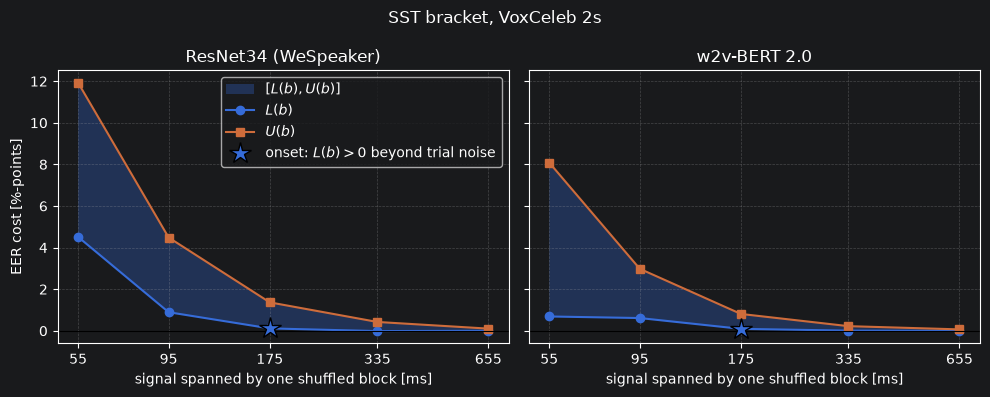

In [3]:
fig, axes = plt.subplots(1, len(brackets), figsize=(5 * len(brackets), 4), sharey=True, squeeze=False)
for ax, (label, bracket) in zip(axes[0], brackets.items()):
    span, lower = bracket["L"]
    _, upper = bracket["U"]
    ax.fill_between(span, lower, upper, alpha=0.3, label="$[L(b), U(b)]$")
    ax.plot(span, lower, "o-", label="$L(b)$")
    ax.plot(span, upper, "s-", label="$U(b)$")
    mark_onset(ax, bracket, "L", color="C0", label="onset: $L(b) > 0$ beyond trial noise")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xticks(span, [f"{s:.0f}" for s in span])
    ax.minorticks_off()
    ax.set_title(label)
    ax.set_xlabel("signal spanned by one shuffled block [ms]")
    ax.grid(alpha=0.3, linestyle="--")
axes[0][0].set_ylabel("EER cost [%-points]")
axes[0][0].legend()
fig.suptitle(f"SST bracket, VoxCeleb {VARIANT}")
plt.tight_layout()

## Models compared

$[L_{norm}(b), U_{norm}(b)]$, the band relative to each model's headroom to chance, $50\% - EER(OS)$.

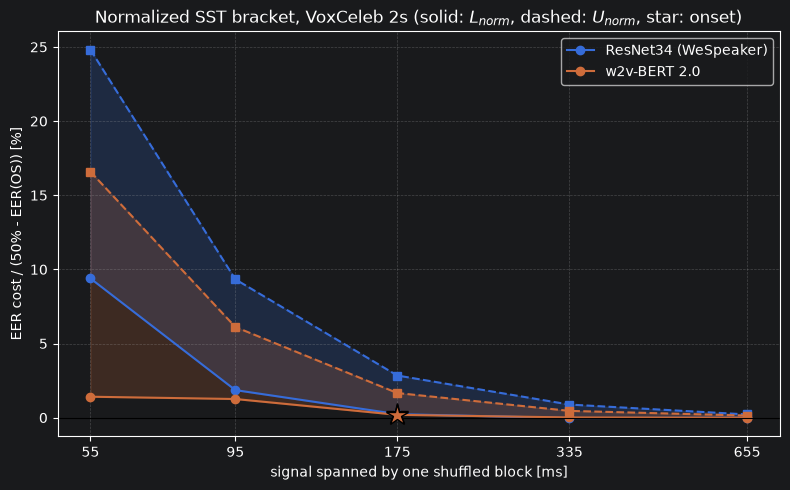

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, bracket in brackets.items():
    span, lower = bracket["L_norm"]
    _, upper = bracket["U_norm"]
    line, = ax.plot(span, lower, "o-", label=label)
    ax.plot(span, upper, "s--", color=line.get_color())
    ax.fill_between(span, lower, upper, color=line.get_color(), alpha=0.2)
    mark_onset(ax, bracket, "L_norm", color=line.get_color())
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
spans = sorted({s for bracket in brackets.values() for s in bracket["L_norm"][0]})
ax.set_xticks(spans, [f"{s:.0f}" for s in spans])
ax.minorticks_off()
ax.set_xlabel("signal spanned by one shuffled block [ms]")
ax.set_ylabel("EER cost / (50% - EER(OS)) [%]")
ax.set_title(f"Normalized SST bracket, VoxCeleb {VARIANT} (solid: $L_{{norm}}$, dashed: $U_{{norm}}$, star: onset)")
ax.grid(alpha=0.3, linestyle="--")
ax.legend()
plt.tight_layout()

## EER(GO_b) and EER(GS_b) per model

The two terms of $L(b) = EER(GS_b) - EER(GO_b)$: the same blocks, spread over the utterance in their original order (GO, solid) or shuffled (GS, dashed), and their difference $L(b)$ (dash-dotted). Dotted: each model's $EER(OS)$.

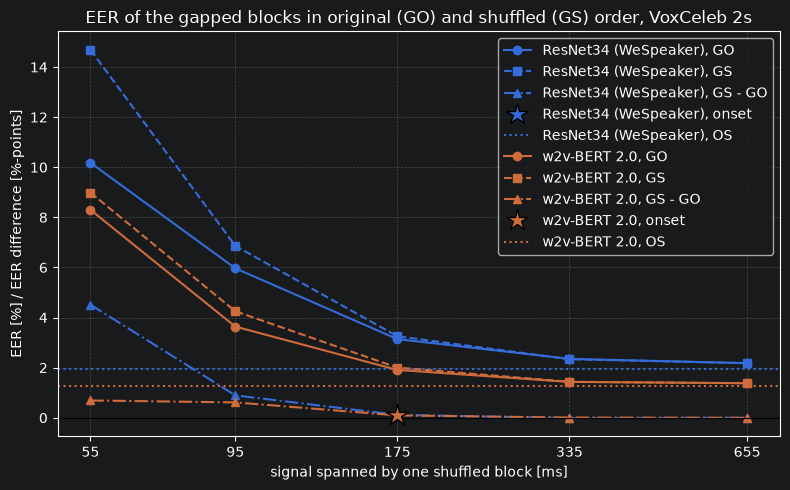

In [5]:
def plot_eers(brackets, variant):
    """EER(GO_b), EER(GS_b), their difference L(b) and EER(OS) per model."""
    fig, ax = plt.subplots(figsize=(8, 5))
    for label, bracket in brackets.items():
        span, go = bracket["GO"]
        line, = ax.plot(span, go, "o-", label=f"{label}, GO")
        ax.plot(*bracket["GS"], "s--", color=line.get_color(), label=f"{label}, GS")
        ax.plot(*bracket["L"], "^-.", color=line.get_color(), label=f"{label}, GS - GO")
        mark_onset(ax, bracket, "L", color=line.get_color(), label=f"{label}, onset")
        ax.axhline(bracket["OS"], color=line.get_color(), linestyle=":", label=f"{label}, OS")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    spans = sorted({s for bracket in brackets.values() for s in bracket["GO"][0]})
    ax.set_xticks(spans, [f"{s:.0f}" for s in spans])
    ax.minorticks_off()
    ax.set_xlabel("signal spanned by one shuffled block [ms]")
    ax.set_ylabel("EER [%] / EER difference [%-points]")
    ax.set_title(f"EER of the gapped blocks in original (GO) and shuffled (GS) order, VoxCeleb {variant}")
    ax.grid(alpha=0.3, linestyle="--")
    ax.legend()
    plt.tight_layout()


plot_eers(brackets, VARIANT)

## EER(GO_b) and EER(GS_b) per model, VoxCeleb 3s

The same as above, for the runs on 3 s test windows.

ResNet34 (WeSpeaker): WeSpeakerResNet34-voxceleb-OS-3s (gonwd207, finished), 3 run(s)
w2v-BERT 2.0: W2VBertSV-voxceleb-OS-3s (ys11pzws, finished), 3 run(s)
WavLM-ECAPA: no completed run


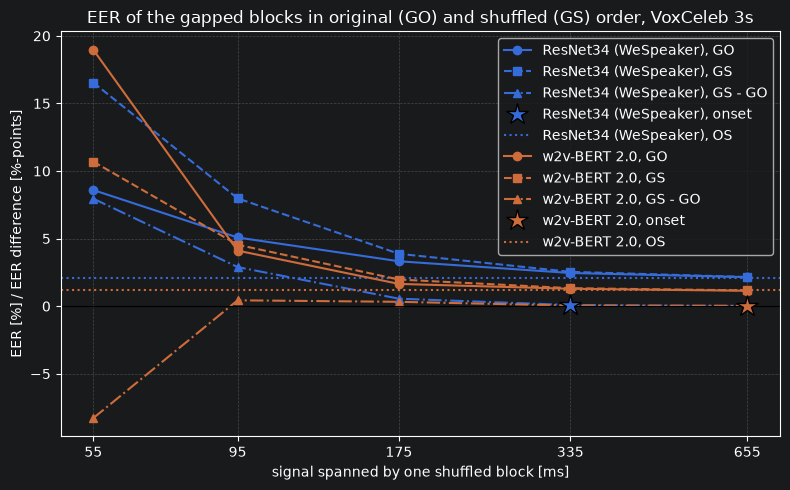

In [6]:
plot_eers(fetch_brackets(api, "3s"), "3s")